# ピークホールドとエンベロープ

入力の山(最大値)を**覚えておく**回路(ピークホールド)と、山をなぞって**包絡線**(エンベロープ)を取り出す回路(エンベロープフォロワ)です。信号の最大値を測る、音の大きさに合わせてメーターの針を動かす、AM ラジオの電波から音声を取り出す(検波)、といった使い方をします。

この回では、山を覚えてリセットする、コンデンサの放電、時定数とリプル、の 3 つを見ます。

## 回路

![ピーク検出回路](05_peak_envelope/circuit.svg)

[整流回路](04_rectifier.ipynb)のスーパーダイオードで、コンデンサ C を充電する回路です。C の下のグランドは、Mimic でいえば Vref です。

- 入力が C の電圧より高いと、ダイオードに電流が流れて、C は入力と同じ電圧まで充電されます(オペアンプのおかげで 0.6 V 下がらない)。
- 入力が C の電圧より低いと、ダイオードが切れて、C は電圧を**保ちます**。

C と並べた抵抗 R は、C の電荷を少しずつ逃がします(**放電**)。R がなければ山をずっと覚えている**ピークホールド**、R があれば山が下がるとそれについていく**エンベロープフォロワ**です。スイッチ(reset)は C をショートして、覚えた値を消します。

## 原理

| | 入力が上がったとき | 入力が下がったとき |
|---|---|---|
| ピークホールド(R なし) | すぐに追いつく | 最大値を保つ(reset で消す) |
| エンベロープフォロワ(R あり) | すぐに追いつく | 時定数 $\tau = RC$ で Vref に向かって下がる |

![ピークホールドとエンベロープフォロワ(模式図)](05_peak_envelope/response.svg)

エンベロープフォロワの時定数 $\tau$ は、短すぎても長すぎても困ります。

- 短いと、入力の山と山のあいだに大きく下がってしまい、出力がぎざぎざになります(**リプル**)。
- 長いと、入力の振幅が小さくなったときに、ついていくのが遅れます。

目安は、入力の周期 ≪ $\tau$ ≪ 振幅が変わる時間(AM ラジオなら、搬送波の周期 ≪ $\tau$ ≪ 音声の周期)です。

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.peak_hold(polarity)` | `mimic.setPeakHold(polarity)` | ピークホールド(R なし) |
| `lab.mimic.envelope(decay, polarity)` | `mimic.setEnvelopeFollower(decay, polarity)` | エンベロープフォロワ。decay = $\tau = RC$ [µs] |

- polarity は `"pos"`(Vref より上の山)か `"neg"`(Vref より下の谷。ダイオードを逆向きにした回路)。省くと `"pos"`。`"neg"` は谷の電圧を保ち、Vref に向かって上がって戻ります。
- C の下は Vref につながっているので、リセットした直後の値は Vref です。`"pos"` は Vref より上の山だけ、`"neg"` は Vref より下の谷だけをつかみます。
- 例:$\tau$ = 10 ms は、C = 1 µF、R = 10 kΩ にあたります。
- 設定を変えても、覚えた値は残ります。**リセット**するには、いったん別のモード(バイパス)にしてからピークホールドにします。下の `reset_peak()` が、回路の reset のスイッチを押すことにあたります。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, fit_sine

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261125)

波形(左)と、入出力特性(右:CH1 を横軸、CH2 を縦軸にした点)を並べて描く関数と、リセットのスイッチを押す関数です。

In [2]:
def scope_xy(t, ch1, ch2, label="output", xlim=None):
    # Left: the oscilloscope; right: the input-output characteristic (CH1 across, CH2 up)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
    ax1.plot(t * 1e3, ch1, label="CH1: input")
    ax1.plot(t * 1e3, ch2, label=f"CH2: {label}")
    if xlim:
        ax1.set_xlim(*xlim)
    ax1.set_ylim(-0.2, 5.2)
    ax1.set_xlabel("Time [ms]")
    ax1.set_ylabel("Voltage [V]")
    ax1.grid(True)
    ax1.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)
    ax2.plot(ch1, ch2, ".-", lw=0.5, ms=2, color="C2")   # thin lines show the transitions
    ax2.set_xlim(0, 5)
    ax2.set_ylim(-0.2, 5.2)
    ax2.set_aspect("equal")
    ax2.set_xlabel("CH1: input [V]")
    ax2.set_ylabel("CH2: output [V]")
    ax2.grid(True)
    fig.tight_layout()
    plt.show()


def reset_peak(polarity="pos"):
    # Press the reset switch: switching the mode clears the held peak (like shorting C)
    lab.mimic.bypass()
    lab.mimic.peak_hold(polarity)

## 実験 1:山を覚える

ピークホールドで、次の順に入力の振幅を変えて、そのたびに出力を取り込みます(正弦波 50 Hz)。

1. リセットして、振幅 0.5 V → 出力は 3.0 V(2.5 + 0.5)
2. 振幅を 1.0 V に → 3.5 V に上がる
3. 振幅を 0.3 V に → 3.5 V のまま(最大値を覚えている)
4. リセットする → 2.8 V(今の振幅 0.3 V の山)

1. reset, 0.5 V   : output 2.999 V
2. 1.0 V          : output 3.499 V
3. 0.3 V          : output 3.499 V
4. reset (0.3 V)  : output 2.799 V


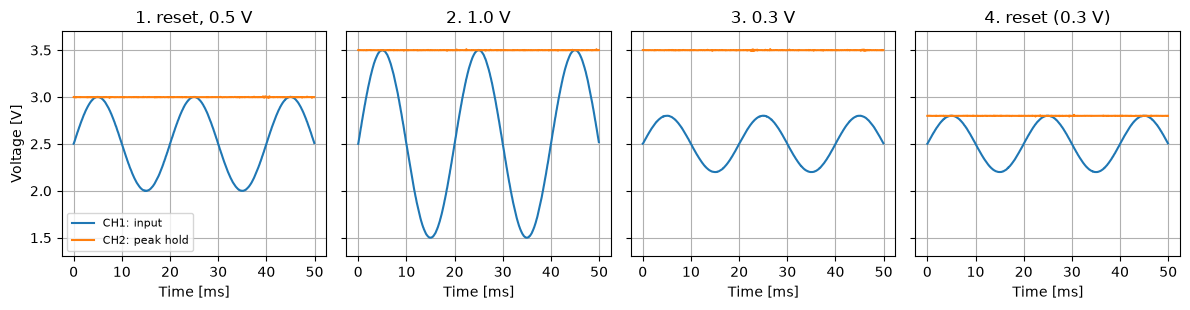

In [3]:
steps = [("1. reset, 0.5 V", True, 0.5), ("2. 1.0 V", False, 1.0),
         ("3. 0.3 V", False, 0.3), ("4. reset (0.3 V)", True, 0.3)]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, (title, reset, amp) in zip(axes, steps):
    lab.fg.sine(50, amp)
    if reset:
        reset_peak()
    time.sleep(0.1)
    t, ch1, ch2 = lab.scope.capture(1000)   # 50 ms
    print(f"{title:18s}: output {ch2.mean():.3f} V")
    ax.plot(t * 1e3, ch1, label="CH1: input")
    ax.plot(t * 1e3, ch2, label="CH2: peak hold")
    ax.set_title(title)
    ax.set_xlabel("Time [ms]")
    ax.grid(True)
axes[0].set_ylabel("Voltage [V]")
axes[0].set_ylim(1.3, 3.7)
axes[0].legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

振幅を小さくしても(3)、出力は前の山の 3.5 V を保っています。リセットのスイッチを押すと(4)、覚えた値が消えて、今の入力の山(2.8 V)を覚え直します。

## 実験 2:放電を見る

エンベロープフォロワ($\tau$ = 10 ms)に、10 Hz、振幅 1 V の方形波を入れます。前半の 50 ms は入力が 3.5 V なので、出力も 3.5 V です。後半の 50 ms は入力が Vref より下(1.5 V)なので、ダイオードが切れて、C が R で放電し、出力は $\tau$ = 10 ms で Vref に向かって下がるはずです。下がっていく部分から $\tau$ を求めます。

decay time: 9.8 ms (setting 10.0 ms)


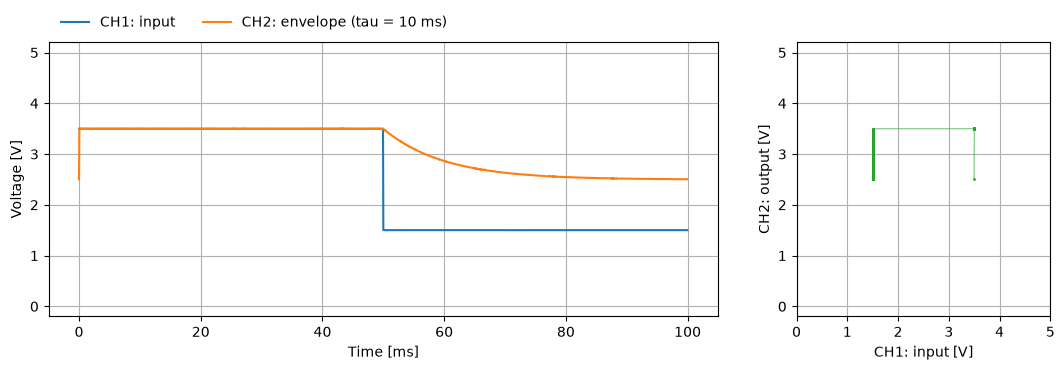

In [4]:
TAU = 10000   # decay time [us]

lab.fg.square(10, 1.0)
lab.mimic.envelope(TAU)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s: one period
fall = (t > 0.051) & (t < 0.09) & (ch2 - 2.5 > 0.03)
slope = np.polyfit(t[fall], np.log(ch2[fall] - 2.5), 1)[0]
print(f"decay time: {-1 / slope * 1e3:.1f} ms (setting {TAU / 1000:.1f} ms)")
scope_xy(t, ch1, ch2, f"envelope (tau = {TAU / 1000:.0f} ms)")

下がり方は、コンデンサの放電と同じ指数関数です。$\tau$ 後には 1 V の 37 %(0.37 V)、$3\tau$ 後には 5 %(0.05 V)まで下がります。入出力特性(右)は、同じ入力の電圧(1.5 V)に対して、出力がいろいろな値をとる縦の線になります。出力が今の入力だけでは決まらず、過去の入力(覚えている値)で決まるからです。

## 実験 3:時定数とリプル

100 Hz、振幅 1 V の正弦波を、$\tau$ = 2 ms、10 ms、50 ms のエンベロープフォロワに入れて、出力のぎざぎざ(リプル:最大 − 最小)を比べます。

tau =    2 ms: ripple 970 mV
tau =   10 ms: ripple 557 mV
tau =   50 ms: ripple 168 mV


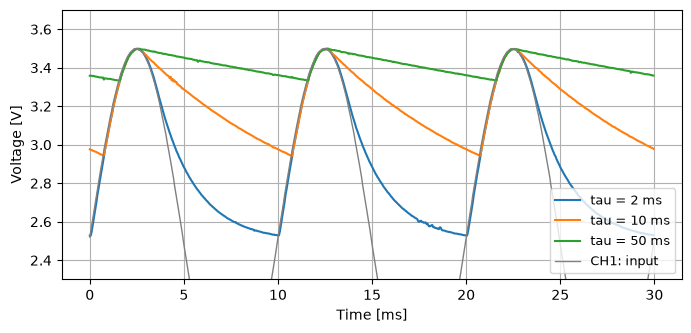

In [5]:
lab.fg.sine(100, 1.0)
fig, ax = plt.subplots(figsize=(8, 3.5))
for tau in (2000, 10000, 50000):
    lab.mimic.envelope(tau)
    time.sleep(0.5)
    t, ch1, ch2 = lab.scope.capture(600)   # 30 ms: 3 periods
    print(f"tau = {tau / 1000:4.0f} ms: ripple {(ch2.max() - ch2.min()) * 1e3:.0f} mV")
    ax.plot(t * 1e3, ch2, label=f"tau = {tau / 1000:.0f} ms")
ax.plot(t * 1e3, ch1, color="gray", lw=1, label="CH1: input")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.set_ylim(2.3, 3.7)
ax.grid(True)
ax.legend(loc="lower right", fontsize=9)
plt.show()

$\tau$ が長いほど、山と山のあいだ(10 ms)に下がる量が小さく、リプルが小さくなります。$\tau$ が周期(10 ms)と同じくらいだと、リプルは山の高さの半分ほどにもなります。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 振幅が下がったときについていく

エンベロープフォロワで、正弦波(100 Hz)の振幅を 1.0 V から 0.5 V に下げます。下げる前に 50 ms、下げた直後から 0.2 秒取り込み、つなげて描きます(時間 0 が振幅を下げたところ。下げてから取り込みが始まるまでの十数 ms は取り込めないので、そこは詰めてあります)。出力が新しい山(3.0 V)まで下がっていくようすを、時定数を変えて見ます。点線のところで出力が少し下に飛んで見えるのは、取り込めない十数 ms のあいだにも出力が下がり続けているためです(入力の位相も飛んでいます)。
<details><summary>ヒント</summary>

`TAU` を 100000 → 30000 → 300000 → 10000 と変えてみましょう。出力(Vref からの高さ)が 1.0 V から 0.5 V まで下がるのにかかる時間は $\tau \ln 2$ ≈ 0.7 $\tau$ です。

- 100 ms:リプルはほとんどなく、約 70 ms かけて 3.0 V まで下がります。
- 30 ms:約 20 ms でついていき、リプルは少し大きくなります。
- 300 ms:約 0.2 秒かかり、取り込んだ範囲ではまだ下がりきりません。
- 10 ms:リプルが大きくなります。振幅を変えてから取り込みが始まるまでに十数 ms かかる(PC と Arduino のやり取り)ので、取り込みの最初にはもう下がりきっています。

リプルの小ささと、ついていく速さは両立しません。これが時定数の選び方のかね合いです。

</details>

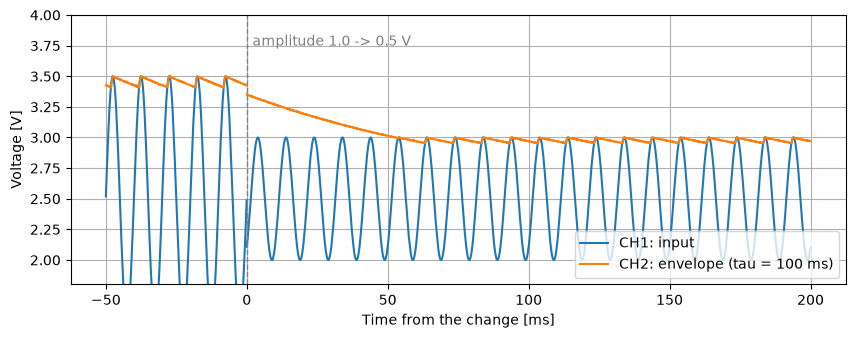

In [6]:
TAU = 100000   # decay time [us]

lab.mimic.envelope(TAU)
lab.fg.sine(100, 1.0)
time.sleep(1.0)
tb, b1, b2 = lab.scope.capture(1000)                # 50 ms before the change
lab.fg.sine(100, 0.5)                               # the amplitude falls
ta, a1, a2 = lab.scope.capture(2000, fs=10000, sync=False)   # 0.2 s right after the change

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot((tb - 0.05) * 1e3, b1, color="C0", label="CH1: input")
ax.plot((tb - 0.05) * 1e3, b2, color="C1", label=f"CH2: envelope (tau = {TAU / 1000:.0f} ms)")
ax.plot(ta * 1e3, a1, color="C0")
ax.plot(ta * 1e3, a2, color="C1")
ax.axvline(0, color="gray", ls="--", lw=1)
ax.text(2, 3.75, "amplitude 1.0 -> 0.5 V", color="gray")
ax.set_ylim(1.8, 4.0)
ax.set_xlabel("Time from the change [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend(loc="lower right")
plt.show()

### 2. 谷をつかむ(極性)

中心 2.0 V、振幅 0.5 V の正弦波(1.5〜2.5 V。いつも Vref 以下)を、ピークホールドの 2 つの極性に入れます。
<details><summary>ヒント</summary>

`POLARITY` を `"pos"` と `"neg"` にしてみましょう。`"pos"` は Vref より上の山をつかみますが、入力が Vref を超えないので、出力は Vref(2.5 V)のままです。`"neg"` はダイオードを逆向きにした回路で、谷の電圧 **1.5 V** をつかみます(Vref から 1.0 V 下)。

</details>

output 1.496 V (-1.004 V from Vref)


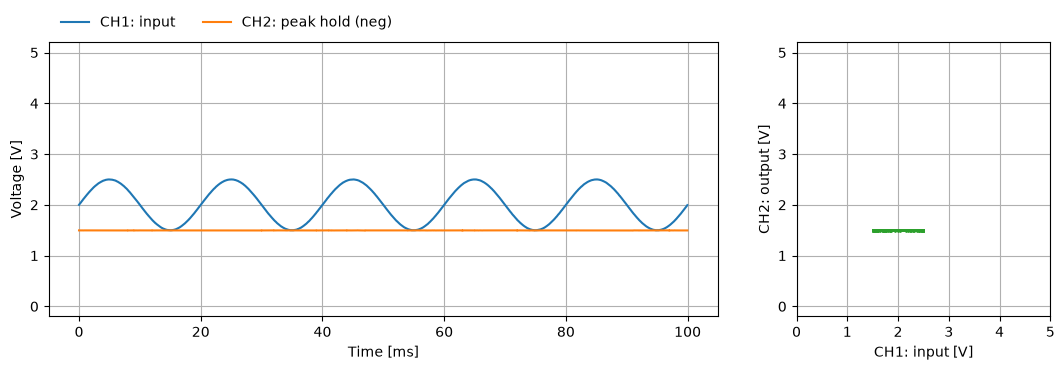

In [7]:
POLARITY = "neg"   # "pos" or "neg"

lab.fg.sine(50, 0.5, 2.0)
reset_peak(POLARITY)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"output {ch2.mean():.3f} V ({ch2.mean() - 2.5:+.3f} V from Vref)")
scope_xy(t, ch1, ch2, f"peak hold ({POLARITY})")

## まとめ

- ピーク検出回路は、スーパーダイオードでコンデンサを充電し、入力の山を保つ。R なしならピークホールド(reset のスイッチで消す)、R ありならエンベロープフォロワ。
- エンベロープフォロワは、時定数 $\tau = RC$ で放電する。$\tau$ が短いとリプルが大きく、長いと振幅の変化についていくのが遅い。
- Mimic では `peak_hold(polarity)`、`envelope(decay, polarity)`。`"neg"` は谷をつかむ。リセットは、いったんバイパスにしてからピークホールドにする。


最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [8]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()